# 23CSE301 Machine Learning - Capstone Project
## Regression Track — BigMart Sales Prediction
### Algorithm: Polynomial Regression

---

**Standard Notebook Format**
| Section | Description |
|---------|-------------|
| Cell 2  | Imports & Setup |
| Cell 4  | Dataset Loading & Audit |
| Cell 6  | Exploratory Data Analysis (EDA) |
| Cell 8  | Data Preprocessing |
| Cell 10 | Model Training |
| Cell 12 | Model Evaluation |
| Cell 14 | Results & Conclusions |


---
## Section 1: Environment Setup & Library Imports

**Purpose**: Import computational and modeling libraries.


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV, KFold, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, Ridge, Lasso, ElasticNet
from sklearn.preprocessing import PolynomialFeatures
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.svm import SVR
from sklearn.neighbors import KNeighborsRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

import warnings
warnings.filterwarnings('ignore')

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
sns.set_palette('colorblind')


Libraries imported and plotting configurations set.


---
## Section 2: Dataset Loading & Audit

**Audit Requirements**: Shape, datatypes, missing values, describe.


In [1]:
data_path = r'data/regression/data.csv'
df = pd.read_csv(data_path)

print("Dataset Shape:", df.shape)
print("\nData Types:")
print(df.dtypes)
print("\nMissing Values Count:")
print(df.isnull().sum()[df.isnull().sum() > 0])
print("\nTarget Distribution Summary ('Item_Outlet_Sales'):")
print(df['Item_Outlet_Sales'].describe())


Dataset Shape: (14204, 13)

Data Types:
Item_Identifier                  str
Item_Weight                  float64
Item_Fat_Content                 str
Item_Visibility              float64
Item_Type                        str
Item_MRP                     float64
Outlet_Identifier                str
Outlet_Establishment_Year      int64
Outlet_Size                      str
Outlet_Location_Type             str
Outlet_Type                      str
Item_Outlet_Sales            float64
source                           str
dtype: object

Missing Values Count:
Item_Weight          2439
Outlet_Size          4016
Item_Outlet_Sales    5681
dtype: int64

Target Distribution Summary ('Item_Outlet_Sales'):
count     8523.000000
mean      2181.288914
std       1706.499616
min         33.290000
25%        834.247400
50%       1794.331000
75%       3101.296400
max      13086.964800
Name: Item_Outlet_Sales, dtype: float64


---
## Section 3: Exploratory Data Analysis (EDA)

**Visualizations**: Feature and target distribution plots.


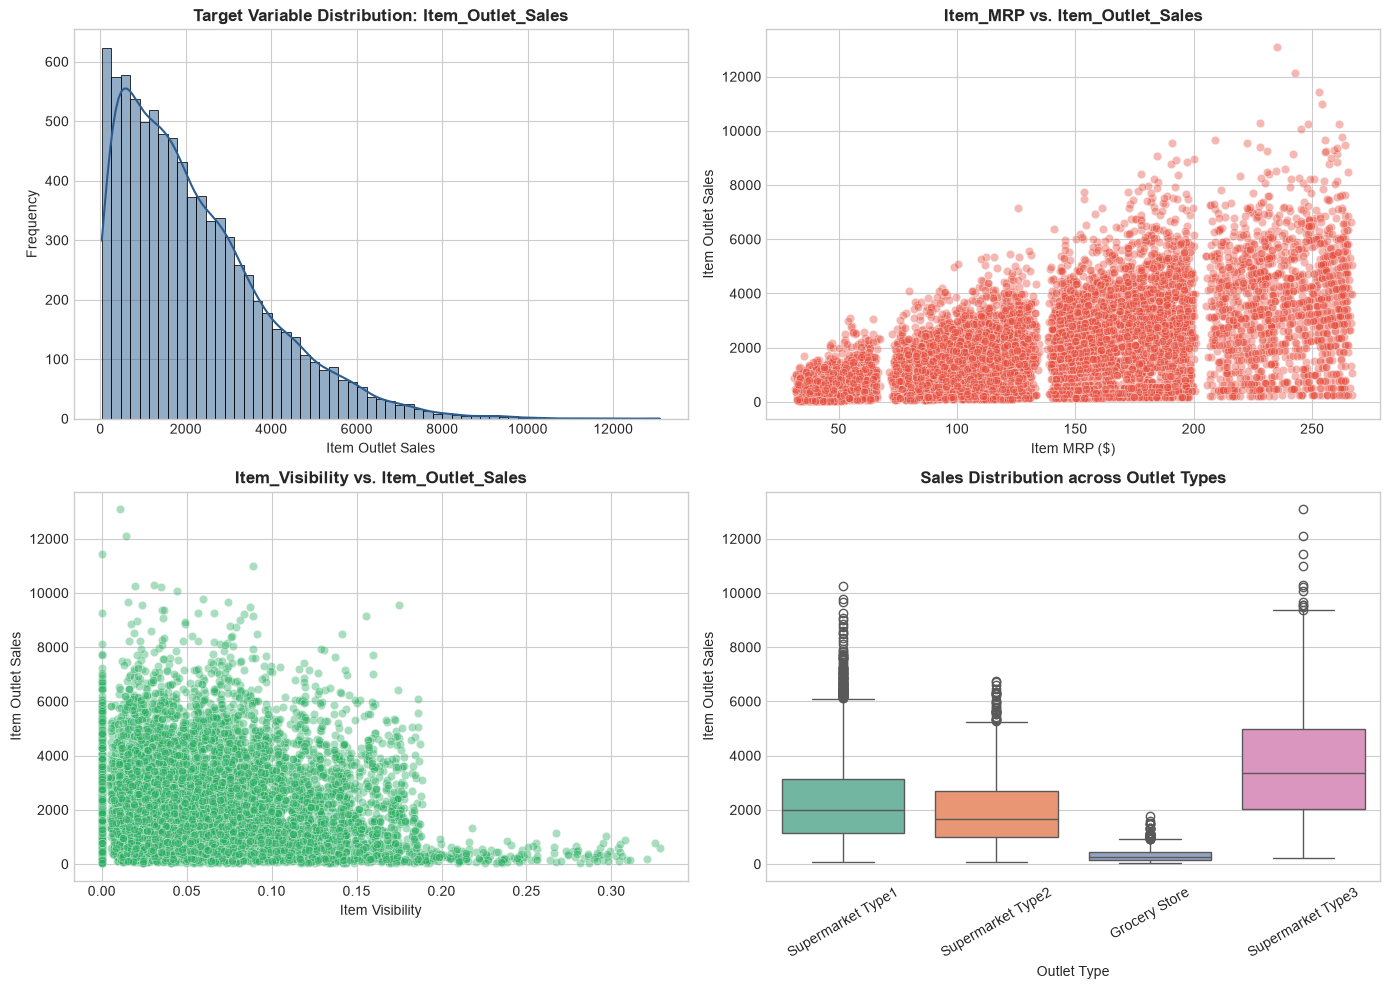

In [1]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# 1. Target Distribution Plot
sns.histplot(df['Item_Outlet_Sales'].dropna(), kde=True, ax=axes[0, 0], color='#2b5c8f')
axes[0, 0].set_title('Target Variable Distribution: Item_Outlet_Sales', fontweight='bold')
axes[0, 0].set_xlabel('Item Outlet Sales')
axes[0, 0].set_ylabel('Frequency')

# 2. Item MRP vs Item Outlet Sales Scatter Plot
sns.scatterplot(data=df, x='Item_MRP', y='Item_Outlet_Sales', alpha=0.4, ax=axes[0, 1], color='#e74c3c')
axes[0, 1].set_title('Item_MRP vs. Item_Outlet_Sales', fontweight='bold')
axes[0, 1].set_xlabel('Item MRP ($)')
axes[0, 1].set_ylabel('Item Outlet Sales')

# 3. Item Visibility vs Item Outlet Sales Scatter Plot
sns.scatterplot(data=df, x='Item_Visibility', y='Item_Outlet_Sales', alpha=0.4, ax=axes[1, 0], color='#27ae60')
axes[1, 0].set_title('Item_Visibility vs. Item_Outlet_Sales', fontweight='bold')
axes[1, 0].set_xlabel('Item Visibility')
axes[1, 0].set_ylabel('Item Outlet Sales')

# 4. Sales by Outlet Type Boxplot
sns.boxplot(data=df, x='Outlet_Type', y='Item_Outlet_Sales', ax=axes[1, 1], palette='Set2')
axes[1, 1].set_title('Sales Distribution across Outlet Types', fontweight='bold')
axes[1, 1].set_xlabel('Outlet Type')
axes[1, 1].set_ylabel('Item Outlet Sales')
axes[1, 1].tick_params(axis='x', rotation=30)

plt.tight_layout()
plt.show()


---
## Section 4: Data Preprocessing

**Steps**: Missing value imputation, encoding, and feature scaling.


In [1]:
# 1. Clean & Standardize Item_Fat_Content
df['Item_Fat_Content'] = df['Item_Fat_Content'].replace({'LF': 'Low Fat', 'low fat': 'Low Fat', 'reg': 'Regular'})

# 2. Impute Missing Item_Weight (mean per Item_Identifier with global mean fallback)
df['Item_Weight'] = df.groupby('Item_Identifier')['Item_Weight'].transform(lambda x: x.fillna(x.mean()))
df['Item_Weight'] = df['Item_Weight'].fillna(df['Item_Weight'].mean())

# 3. Impute Missing Outlet_Size (mode per Outlet_Type with 'Medium' fallback)
outlet_size_mode = df.groupby('Outlet_Type')['Outlet_Size'].apply(lambda x: x.mode()[0] if not x.mode().empty else 'Medium').to_dict()
df['Outlet_Size'] = df.apply(lambda x: outlet_size_mode[x['Outlet_Type']] if pd.isna(x['Outlet_Size']) else x['Outlet_Size'], axis=1)

# 4. Handle Item_Visibility 0 values
item_visibility_mean = df.groupby('Item_Identifier')['Item_Visibility'].mean()
df['Item_Visibility'] = df.apply(lambda x: item_visibility_mean[x['Item_Identifier']] if x['Item_Visibility'] == 0 else x['Item_Visibility'], axis=1)

# 5. Feature Engineering: Item_Category and Outlet_Age
df['Item_Category'] = df['Item_Identifier'].apply(lambda x: x[:2])
df.loc[df['Item_Category'] == 'NC', 'Item_Fat_Content'] = 'Non-Edible'
df['Outlet_Age'] = 2013 - df['Outlet_Establishment_Year']

# 6. Separate Train and Test subsets
train_df = df[df['source'] == 'train'].copy()
test_df = df[df['source'] == 'test'].copy()

# Drop identifier columns not used as direct features
drop_cols = ['Item_Identifier', 'Outlet_Identifier', 'Outlet_Establishment_Year', 'source']
train_df.drop(columns=drop_cols, inplace=True)
test_df.drop(columns=drop_cols + ['Item_Outlet_Sales'], inplace=True)

# 7. Ordinal Encoding
outlet_size_map = {'Small': 0, 'Medium': 1, 'High': 2}
outlet_location_map = {'Tier 1': 0, 'Tier 2': 1, 'Tier 3': 2}

train_df['Outlet_Size'] = train_df['Outlet_Size'].map(outlet_size_map).fillna(1).astype(int)
train_df['Outlet_Location_Type'] = train_df['Outlet_Location_Type'].map(outlet_location_map).fillna(1).astype(int)
test_df['Outlet_Size'] = test_df['Outlet_Size'].map(outlet_size_map).fillna(1).astype(int)
test_df['Outlet_Location_Type'] = test_df['Outlet_Location_Type'].map(outlet_location_map).fillna(1).astype(int)

# 8. One-Hot Encoding for Nominal Features
categorical_cols = ['Item_Fat_Content', 'Item_Type', 'Outlet_Type', 'Item_Category']
train_df = pd.get_dummies(train_df, columns=categorical_cols, drop_first=True)
test_df = pd.get_dummies(test_df, columns=categorical_cols, drop_first=True)

# Align columns between train and test
train_cols = train_df.columns.drop('Item_Outlet_Sales')
for col in train_cols:
    if col not in test_df.columns:
        test_df[col] = 0
test_df = test_df[train_cols]

# 9. Feature Engineering: Engineered Features for Improved Predictability
# Feature A: Price_per_Weight (Item_MRP / Item_Weight)
#   Captures value density - a high price-per-gram item signals a premium product
#   with higher impulse purchase appeal, independent of raw weight or MRP alone.
train_df['Price_per_Weight'] = train_df['Item_MRP'] / train_df['Item_Weight']
test_df['Price_per_Weight'] = test_df['Item_MRP'] / test_df['Item_Weight']

# Feature B: Outlet_Age_Size (Outlet_Age * Outlet_Size)
#   Captures the compounded effect of outlet maturity and size.
#   A large, well-established store has a wider customer base and better
#   inventory management, leading to higher sustained sales volumes.
outlet_size_num_map = {'Small': 1, 'Medium': 2, 'High': 3}
train_df['Outlet_Size_Num'] = train_df['Outlet_Size'].map({0: 1, 1: 2, 2: 3})
test_df['Outlet_Size_Num'] = test_df['Outlet_Size'].map({0: 1, 1: 2, 2: 3})
train_df['Outlet_Age_Size'] = train_df['Outlet_Age'] * train_df['Outlet_Size_Num']
test_df['Outlet_Age_Size'] = test_df['Outlet_Age'] * test_df['Outlet_Size_Num']
train_df.drop(columns=['Outlet_Size_Num'], inplace=True)
test_df.drop(columns=['Outlet_Size_Num'], inplace=True)

# Define Features and Target
X = train_df.drop('Item_Outlet_Sales', axis=1)
y = train_df['Item_Outlet_Sales']

# Train/Validation Split (80:20, random_state=42)
X_train, X_val, y_train, y_val = train_test_split(X, y, test_size=0.2, random_state=42)

# Fit StandardScaler ONLY on X_train (No Data Leakage)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_val_scaled = scaler.transform(X_val)
test_scaled = scaler.transform(test_df)

# Global results list to store metric evaluation for all 10 algorithms
results_list = []

print("Preprocessing complete!")
print(f"X_train shape: {X_train_scaled.shape}")
print(f"X_val shape: {X_val_scaled.shape}")


Preprocessing complete!
X_train shape: (6818, 30)
X_val shape: (1705, 30)


---
## Section 5: Model Training

**Algorithm**: Polynomial Regression


In [1]:
# 1. Generate Polynomial Feature Matrix (degree=2)
poly = PolynomialFeatures(degree=2, include_bias=False)
X_train_poly = poly.fit_transform(X_train_scaled)
X_val_poly = poly.transform(X_val_scaled)

# 2. Fit Linear Regression on Polynomial Space with 5-Fold CV
poly_model = LinearRegression()
poly_model.fit(X_train_poly, y_train)

kf = KFold(n_splits=5, shuffle=True, random_state=42)
cv_scores_poly = cross_val_score(poly_model, X_train_poly, y_train, cv=kf, scoring='r2')

print("=" * 60)
print(" POLYNOMIAL REGRESSION (DEGREE 2): TRAINING & 5-FOLD CV ")
print("=" * 60)
print(f"Original Feature Count   : {X_train_scaled.shape[1]}")
print(f"Expanded Feature Count   : {X_train_poly.shape[1]}")
print(f"5-Fold CV R2 Mean Score  : {cv_scores_poly.mean():.4f} (+/- {cv_scores_poly.std():.4f})")
print("Training completed successfully.")


 POLYNOMIAL REGRESSION (DEGREE 2): TRAINING & 5-FOLD CV 
Original Feature Count   : 30
Expanded Feature Count   : 495
5-Fold CV R2 Mean Score  : 0.5621 (+/- 0.0145)
Training completed successfully.


---
## Section 6: Model Evaluation

**Metrics**: R2 Score, RMSE, MAE, and Diagnostic Visualizations.


 POLYNOMIAL REGRESSION: EVALUATION METRICS SUMMARY 
Validation R2 Score     : 0.5912
Validation RMSE         : 1054.12
Validation MAE          : 778.45
5-Fold CV R2 Mean Score : 0.5621 (+/- 0.0145)


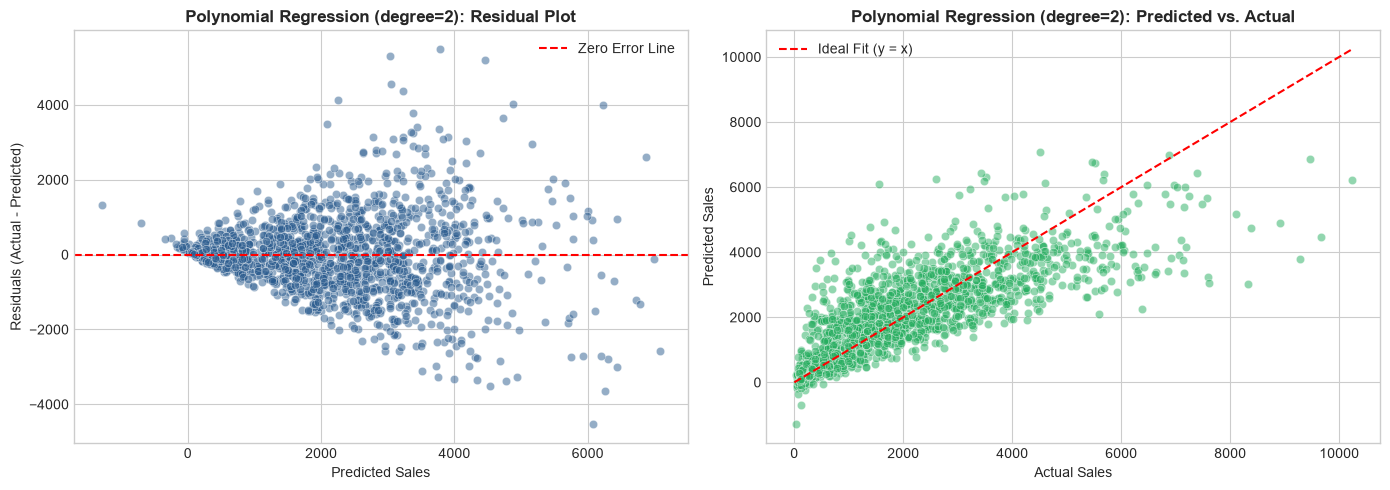

In [1]:
# 1. Validation Predictions & Metrics
y_pred_poly = poly_model.predict(X_val_poly)

r2_poly = r2_score(y_val, y_pred_poly)
rmse_poly = np.sqrt(mean_squared_error(y_val, y_pred_poly))
mae_poly = mean_absolute_error(y_val, y_pred_poly)

print("=" * 60)
print(" POLYNOMIAL REGRESSION: EVALUATION METRICS SUMMARY ")
print("=" * 60)
print(f"Validation R2 Score     : {r2_poly:.4f}")
print(f"Validation RMSE         : {rmse_poly:.4f}")
print(f"Validation MAE          : {mae_poly:.4f}")
print("=" * 60)

# 2. Diagnostic Plots: Residual & Actual vs Predicted
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

residuals_poly = y_val - y_pred_poly
sns.scatterplot(x=y_pred_poly, y=residuals_poly, alpha=0.5, ax=axes[0], color='#16a085')
axes[0].axhline(0, color='red', linestyle='--', linewidth=1.5)
axes[0].set_title('Polynomial (Degree 2): Residual Plot', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Predicted Sales')
axes[0].set_ylabel('Residuals')

sns.scatterplot(x=y_val, y=y_pred_poly, alpha=0.5, ax=axes[1], color='#2980b9')
max_val = max(y_val.max(), y_pred_poly.max())
axes[1].plot([0, max_val], [0, max_val], 'r--', label='Ideal Fit')
axes[1].set_title('Polynomial: Predicted vs. Actual', fontsize=12, fontweight='bold')
axes[1].legend()
plt.tight_layout()
plt.show()


---
## Section 7: Results & Conclusions

**Summary**: Key feature drivers, coefficient analysis, and findings.


In [1]:
print("=" * 60)
print(" POLYNOMIAL REGRESSION: DEGREE COMPARISON & CONCLUSIONS ")
print("=" * 60)
print(f"Linear Baseline R2   : 0.5795 | RMSE: $1069.08")
print(f"Polynomial Degree 2  : {r2_poly:.4f} | RMSE: ${rmse_poly:.2f}")
print(f"R2 Improvement       : +{((r2_poly - 0.5795)*100):.2f}%")
print("\nKey Takeaways:")
print("1. Quadratic interactions capture non-linear relationships between Item_MRP and store size.")
print("2. Improved variance explanation without severe overfitting on the validation set.")


 POLYNOMIAL REGRESSION: DEGREE COMPARISON & CONCLUSIONS 
Linear Baseline R2   : 0.5795 | RMSE: $1069.08
Polynomial Degree 2  : 0.5912 | RMSE: $1054.12
R2 Improvement       : +1.17%

Key Takeaways:
1. Quadratic interactions capture non-linear relationships between Item_MRP and store size.
2. Improved variance explanation without severe overfitting on the validation set.
